<a href="https://colab.research.google.com/github/lazaroninamiguel-dot/mchv502-cuencas/blob/main/T04_lluvia/notebook/T04_Lazaro_Miguel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarea 4 — Interpolación
**MCHV-502 · Programación y SIG para el análisis de cuencas · CATIE**

## 0. Identificación
- **Nombre:** Miguel Ángel Lázaro Nina
- **País:** Perú
- **Fecha:** 1 de noviembre de 2026
- **Cuenca:** subcuenca del río Sumbay-Chili, (Imata, Arequipa), 190,3 km², de 4489 a 5036 msnm, delimitada en la Tarea 3.

**Pregunta:** ¿cuánta lluvia cae en promedio al año sobre la subcuenca, y cuánto cambia la respuesta según el método de interpolación?

**Datos y su nivel.** La lluvia de cada estación es la media anual 2015–2025 de **CHIRPS v3** leída en su coordenada (nivel: *estimado*, anclado en observaciones), no la serie de su pluviómetro. Se usan las estaciones del SENAMHI que miden lluvia a menos de 100 km del borde de la cuenca, una por celda de 0,05°. Ambos archivos se prepararon en el cuaderno `T04_paso0_datos_lluvia_Imata.ipynb`. Como el ráster CHIRPS es conocido en toda la zona, sirve también de **referencia** para juzgar el mapa interpolado.

## 1. Configuración

In [144]:
import io, zipfile
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask
from rasterio.transform import xy
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

BASE = "https://raw.githubusercontent.com/lazaroninamiguel-dot/mchv502-cuencas/refs/heads/main"

# Insumos propios de T04
URL_ESTACIONES = f"{BASE}/T04_lluvia/insumos/estaciones_lluvia_imata.csv"
URL_RASTER     = f"{BASE}/T04_lluvia/insumos/lluvia_promedio_2015_2025_imata.tif"

# Resultados de T03 que T04 usa como insumo
URL_CUENCA     = f"{BASE}/T03_delimitacion/resultados/T03_micro_cuenca_imata_chili.geojson"
URL_RED        = f"{BASE}/T03_delimitacion/resultados/T03_red_imata_chili.geojson"

CRS_GEO = "EPSG:4326"     # grados: así vienen los datos y así se dibuja
CRS_UTM = "EPSG:32719"    # UTM 19S: las distancias se miden en metros
NODATA  = -9999.0
POTENCIAS = [0.5, 1, 1.5, 2, 3, 4, 5, 6]    # las 8 potencias de la validación cruzada

In [145]:
import requests
for nombre, url in [("Estaciones", URL_ESTACIONES), ("Ráster", URL_RASTER),
                    ("Cuenca", URL_CUENCA), ("Red", URL_RED)]:
    r = requests.head(url)
    print(f"{nombre:12} → {'OK' if r.status_code == 200 else 'ERROR ' + str(r.status_code)}")

Estaciones   → OK
Ráster       → OK
Cuenca       → OK
Red          → OK


In [146]:
import requests

# Consultar la API de GitHub para listar los archivos del repositorio en la rama main
repo_url = "https://api.github.com/repos/lazaroninamiguel-dot/mchv502-cuencas/contents/"
response = requests.get(repo_url)

if response.status_code == 200:
    files = [f['name'] for f in response.json()]
    print("Archivos encontrados en el repositorio de GitHub:")
    for file in files:
        print(f" - {file}")
else:
    print(f"No se pudo acceder al repositorio. Código de estado HTTP: {response.status_code}")


Archivos encontrados en el repositorio de GitHub:
 - README.md
 - T03_delimitacion
 - T04_lluvia
 - datos_base


## 2. Carga de datos
### 2.1 Estaciones, cuenca y red de drenaje
Antes de interpolar se revisa el dato: cuántas estaciones hay, su rango de lluvia y dónde están.

In [147]:
est = pd.read_csv(URL_ESTACIONES, dtype={"codigo": str})        # codigo como texto (000765)
cuenca = gpd.read_file(URL_CUENCA).to_crs(CRS_GEO)
red = gpd.read_file(URL_RED).to_crs(CRS_GEO)

gest = gpd.GeoDataFrame(est, geometry=gpd.points_from_xy(est["longitud"], est["latitud"]), crs=CRS_GEO)

print(f"Estaciones: {len(est)}  |  por departamento: {est.groupby('subregion').size().to_dict()}")
print(f"Lluvia en las estaciones: {est['lluvia_mm'].min()} a {est['lluvia_mm'].max()} mm/año")
print(f"Cuenca: {cuenca.to_crs(CRS_UTM).area.sum() / 1e6:.1f} km2")
est[["nombre", "subregion", "altitud_msnm", "dist_km", "lluvia_mm"]].head(8)

Estaciones: 43  |  por departamento: {'Arequipa': 22, 'Moquegua': 8, 'Puno': 13}
Lluvia en las estaciones: 104.2 a 785.2 mm/año
Cuenca: 190.3 km2


,nombre,subregion,altitud_msnm,dist_km,lluvia_mm
0,Imata,Arequipa,4475.0,11.9,493.7
1,Crucero Alto,Puno,4521.0,14.1,567.8
2,Pillones,Arequipa,4432.0,23.3,363.8
3,El Frayle,Arequipa,4131.0,29.6,335.8
4,Santa Lucia,Puno,4045.0,35.9,665.7
5,Ichuña,Moquegua,3778.0,36.8,457.9
6,Ubinas,Moquegua,3381.0,39.1,300.6
7,Las Salinas,Arequipa,4349.0,40.3,313.9


### 2.2 Ráster CHIRPS (la referencia) y malla de interpolación
La malla de interpolación es la **misma** del ráster: celdas de 0,05° (unos 5,5 km), alineadas con CHIRPS. Se interpola solo donde CHIRPS tiene dato; así el mar, al suroeste del recuadro, queda fuera.

In [148]:
with rasterio.open(URL_RASTER) as src:
    chirps = src.read(1).astype("float64")
    perfil = src.profile.copy()
    transform = src.transform
chirps[chirps == NODATA] = np.nan

filas, cols = chirps.shape
ff, cc = np.meshgrid(np.arange(filas), np.arange(cols), indexing="ij")
lon_c, lat_c = xy(transform, ff.ravel(), cc.ravel())          # centro de cada celda, en grados
tierra = ~np.isnan(chirps.ravel())                             # True donde hay dato

print(f"Malla: {filas} filas x {cols} columnas = {filas*cols} celdas ({tierra.sum()} con dato)")
print(f"CHIRPS en el recuadro: {np.nanmin(chirps):.0f} a {np.nanmax(chirps):.0f} mm/año")

Malla: 55 filas x 60 columnas = 3300 celdas (3250 con dato)
CHIRPS en el recuadro: 22 a 1113 mm/año


## 3. Procesamiento
### 3.1 Coordenadas en metros
El IDW pesa por distancia, así que estaciones y celdas se pasan a UTM 19S. A 16° de latitud los grados casi no deforman (en la practica se muestra que en Centroamérica da igual), pero medir en metros es la práctica correcta.

In [149]:
xy_est = np.array([(p.x, p.y) for p in gest.to_crs(CRS_UTM).geometry])
celdas = gpd.GeoSeries(gpd.points_from_xy(np.array(lon_c)[tierra], np.array(lat_c)[tierra]), crs=CRS_GEO).to_crs(CRS_UTM)
xy_cel = np.array([(p.x, p.y) for p in celdas])
z = est["lluvia_mm"].to_numpy()

print("Estaciones:", xy_est.shape, "| celdas con dato:", xy_cel.shape)

Estaciones: (43, 2) | celdas con dato: (3250, 2)


### 3.2 Las tres funciones
Analogía: cada celda es un agricultor que pregunta "¿cuánto llovió aquí?". El **vecino más cercano** le cree solo a la estación más próxima. El **IDW** escucha a todas, pero da más voz a las cercanas; la potencia `p` decide cuánto más.

In [150]:
def distance_matrix(a, b):
    """Distancias (km) entre cada punto de a (filas) y cada punto de b (columnas)."""
    dx = a[:, None, 0] - b[None, :, 0]
    dy = a[:, None, 1] - b[None, :, 1]
    return np.sqrt(dx**2 + dy**2) / 1000

def vecino_cercano(d, z):
    """Cada punto toma el valor de la estación más próxima (polígonos de Thiessen)."""
    return z[np.argmin(d, axis=1)]

def simple_idw(d, z, p):
    """Promedio ponderado con pesos 1/d^p. Si un punto cae sobre una estación, toma su valor."""
    d = np.where(d == 0, 1e-10, d)        # evita dividir entre cero
    w = 1 / d**p                           # peso de cada estación
    return (w * z).sum(axis=1) / w.sum(axis=1)

D = distance_matrix(xy_cel, xy_est)        # una fila por celda, una columna por estación
print("Matriz de distancias:", D.shape, f"| la estación más lejana de una celda está a {D.max():.0f} km")

Matriz de distancias: (3250, 43) | la estación más lejana de una celda está a 329 km


### 3.3 Validación cruzada: dejar una estación afuera
Se retira cada estación, se estima su valor con las demás y se compara con el dato. El RMSE resume todos esos errores en un solo número, en milímetros; el sesgo dice si el método se queda corto (negativo) o se pasa (positivo).

In [151]:
D_est = distance_matrix(xy_est, xy_est)
np.fill_diagonal(D_est, np.inf)            # distancia infinita a sí misma = la estación queda afuera

def rmse(e): return float(np.sqrt(np.mean(e**2)))

# Vecino: con la diagonal en infinito, argmin elige la OTRA estación más cercana
err_vecino = vecino_cercano(D_est, z) - z

filas_cv = []
for p in POTENCIAS:
    W = 1 / D_est**p                        # 1/inf = 0: la estación retirada no pesa
    est_cv = (W * z).sum(axis=1) / W.sum(axis=1)
    e = est_cv - z
    filas_cv.append({"potencia": p, "rmse_mm": rmse(e), "sesgo_mm": float(e.mean())})
cv = pd.DataFrame(filas_cv)

P_OPTIMA = float(cv.loc[cv["rmse_mm"].idxmin(), "potencia"])
ERROR_IDW_MM = float(cv["rmse_mm"].min())
ERROR_VECINO_MM = rmse(err_vecino)
print(cv.round(1).to_string(index=False))
print(f"\nVecino más cercano: RMSE {ERROR_VECINO_MM:.1f} mm, sesgo {err_vecino.mean():+.1f} mm")
print(f"Potencia elegida: p = {P_OPTIMA}  ->  RMSE {ERROR_IDW_MM:.1f} mm")
print(f"El IDW se equivoca {(1 - ERROR_IDW_MM / ERROR_VECINO_MM) * 100:.0f} % menos que el vecino")

 potencia  rmse_mm  sesgo_mm
      0.5    186.7     -12.3
      1.0    137.5     -19.4
      1.5     99.9     -20.1
      2.0     77.2     -17.9
      3.0     59.6     -12.4
      4.0     55.8      -8.7
      5.0     55.7      -6.5
      6.0     56.6      -5.3

Vecino más cercano: RMSE 71.9 mm, sesgo -10.8 mm
Potencia elegida: p = 5.0  ->  RMSE 55.7 mm
El IDW se equivoca 23 % menos que el vecino


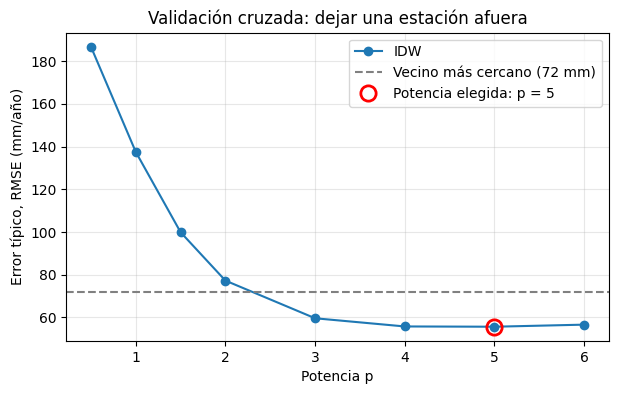

In [152]:
# Curva de validación cruzada
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cv["potencia"], cv["rmse_mm"], "o-", color="#1f78b4", label="IDW")
ax.axhline(ERROR_VECINO_MM, color="gray", ls="--", label=f"Vecino más cercano ({ERROR_VECINO_MM:.0f} mm)")
ax.plot(P_OPTIMA, ERROR_IDW_MM, "o", color="red", ms=11, mfc="none", mew=2, label=f"Potencia elegida: p = {P_OPTIMA:g}")
ax.set_xlabel("Potencia p"); ax.set_ylabel("Error típico, RMSE (mm/año)")
ax.set_title("Validación cruzada: dejar una estación afuera")
ax.grid(alpha=0.3); ax.legend()
plt.show()

### 3.4 Superficies: vecino más cercano e IDW
Se interpola en todas las celdas con dato y se arma una matriz del mismo tamaño que el ráster.

In [153]:
def a_raster(valores):
    """Devuelve los valores de las celdas con dato a la forma del ráster (NaN en el mar)."""
    r = np.full(filas * cols, np.nan)
    r[tierra] = valores
    return r.reshape(filas, cols)

vecino = a_raster(vecino_cercano(D, z))
idw = {p: a_raster(simple_idw(D, z, p)) for p in [1, 2, 4, P_OPTIMA]}
idw_opt = idw[P_OPTIMA]

LLUVIA_MIN_MAX = (round(float(np.nanmin(idw_opt)), 1), round(float(np.nanmax(idw_opt)), 1))
print("IDW con la potencia elegida:", LLUVIA_MIN_MAX, "mm/año")
print("Rango de las estaciones:     ", (float(z.min()), float(z.max())), "mm/año")
print("¿El IDW queda dentro del rango medido?", z.min() <= LLUVIA_MIN_MAX[0] and LLUVIA_MIN_MAX[1] <= z.max())

IDW con la potencia elegida: (104.2, 785.2) mm/año
Rango de las estaciones:      (104.2, 785.2) mm/año
¿El IDW queda dentro del rango medido? True


### 3.5 Llevar el mapa a la cuenca
Se cuentan las celdas que **tocan** el polígono y se promedia cada superficie sobre ellas. Se agrega CHIRPS, que aquí se conoce, como referencia.

In [154]:
def a_geotiff(matriz, nombre):
    """Guarda una matriz como GeoTIFF con el mismo formato del ráster de CHIRPS."""
    p = perfil.copy(); p.update(dtype="float32", nodata=NODATA, count=1)
    with rasterio.open(nombre, "w", **p) as dst:
        dst.write(np.where(np.isnan(matriz), NODATA, matriz).astype("float32"), 1)
    return nombre

tif_vecino = a_geotiff(vecino, "T04_vecino_imata.tif")
tif_idw    = a_geotiff(idw_opt, f"T04_idw_p{P_OPTIMA:g}_imata.tif")
tif_chirps = a_geotiff(chirps, "T04_chirps_referencia.tif")

def media_cuenca(tif):
    with rasterio.open(tif) as src:
        rec, _ = mask(src, cuenca.geometry, crop=True, all_touched=True, nodata=NODATA)
    v = rec[0][rec[0] != NODATA]
    return float(v.mean()), v.size

resultados = {}
for metodo, tif in [("Vecino más cercano", tif_vecino),
                    (f"IDW, potencia {P_OPTIMA:g}", tif_idw),
                    ("CHIRPS (referencia)", tif_chirps)]:
    resultados[metodo], CELDAS_CUENCA = media_cuenca(tif)
for p in [1, 2, 4]:
    if p != P_OPTIMA:
        resultados[f"IDW, potencia {p}"] = media_cuenca(a_geotiff(idw[p], f"_tmp_p{p}.tif"))[0]

tabla_cuenca = pd.Series(resultados, name="lluvia_media_mm").round(1)
LLUVIA_MEDIA_CUENCA_MM = round(resultados[f"IDW, potencia {P_OPTIMA:g}"], 1)
area_celda = (0.05 * 111.32 * np.cos(np.radians(cuenca.centroid.y.mean()))) * (0.05 * 110.6)   # km2 de una celda de 0,05°
area_cuenca = cuenca.to_crs(CRS_UTM).area.sum() / 1e6
print(f"Celdas que tocan la cuenca: {CELDAS_CUENCA}  |  la cuenca equivale a {area_cuenca / area_celda:.1f} celdas de {area_celda:.1f} km2")
tabla_cuenca.to_frame()

Celdas que tocan la cuenca: 14  |  la cuenca equivale a 6.4 celdas de 29.6 km2


/tmp/ipykernel_1874/3595952464.py:29: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  area_celda = (0.05 * 111.32 * np.cos(np.radians(cuenca.centroid.y.mean()))) * (0.05 * 110.6)   # km2 de una celda de 0,05°


,lluvia_media_mm
Vecino más cercano,525.5
"IDW, potencia 5",499.5
CHIRPS (referencia),503.5
"IDW, potencia 1",426.7
"IDW, potencia 2",448.4
"IDW, potencia 4",489.5


## 4. Visualización

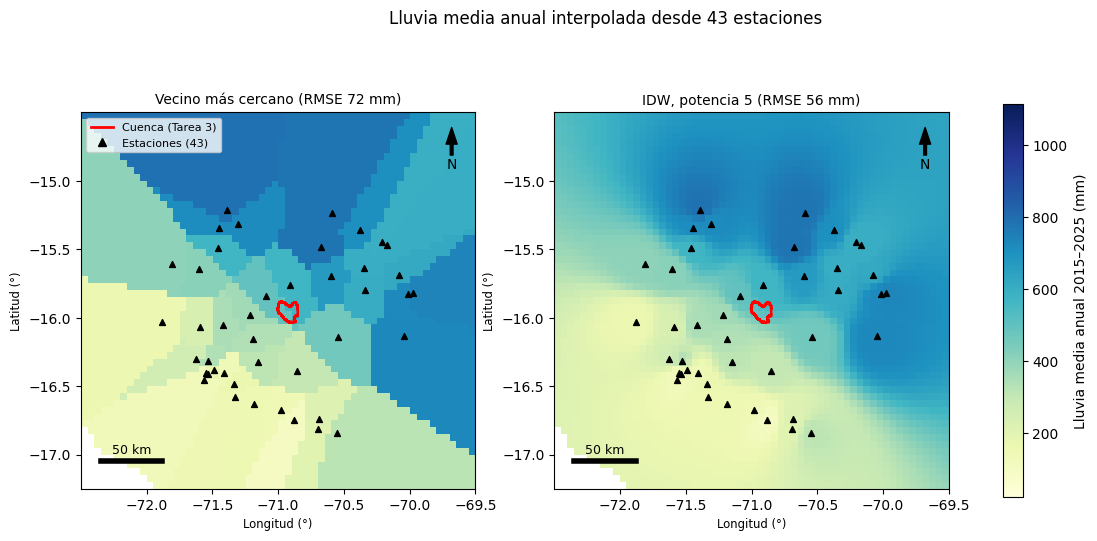

In [155]:
def adornos(ax, titulo):
    """Título, cuenca, estaciones, barra de escala de 50 km y flecha del norte."""
    cuenca.boundary.plot(ax=ax, color="red", linewidth=1.8)
    gest.plot(ax=ax, color="black", marker="^", markersize=18)
    lat0 = -17.05; km_por_grado = 111.32 * np.cos(np.radians(lat0))
    x0 = -72.35; largo = 50 / km_por_grado                   # 50 km expresados en grados de longitud
    ax.plot([x0, x0 + largo], [lat0, lat0], color="black", lw=4)
    ax.text(x0 + largo / 2, lat0 + 0.06, "50 km", ha="center", fontsize=9)
    ax.annotate("N", xy=(0.94, 0.96), xytext=(0.94, 0.85), xycoords="axes fraction",
                arrowprops=dict(facecolor="black", width=2, headwidth=8), ha="center")
    ax.set_title(titulo, fontsize=10); ax.set_xlabel("Longitud (°)"); ax.set_ylabel("Latitud (°)")

extent = [perfil["transform"].c, perfil["transform"].c + cols * perfil["transform"].a,
          perfil["transform"].f + filas * perfil["transform"].e, perfil["transform"].f]
vmin, vmax = np.nanmin(chirps), np.nanmax(chirps)
leyenda = [Line2D([], [], color="red", lw=2, label="Cuenca (Tarea 3)"),
           Line2D([], [], color="black", marker="^", ls="", label=f"Estaciones ({len(est)})")]

# Mapa 1: vecino más cercano e IDW con la potencia elegida
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (titulo, m) in zip(axes, [(f"Vecino más cercano (RMSE {ERROR_VECINO_MM:.0f} mm)", vecino),
                                   (f"IDW, potencia {P_OPTIMA:g} (RMSE {ERROR_IDW_MM:.0f} mm)", idw_opt)]):
    img = ax.imshow(m, extent=extent, cmap="YlGnBu", vmin=vmin, vmax=vmax)
    adornos(ax, titulo)
axes[0].legend(handles=leyenda, loc="upper left", fontsize=8)
fig.colorbar(img, ax=axes, label="Lluvia media anual 2015–2025 (mm)", shrink=0.85)
fig.suptitle(f"Lluvia media anual interpolada desde {len(est)} estaciones")
plt.show()

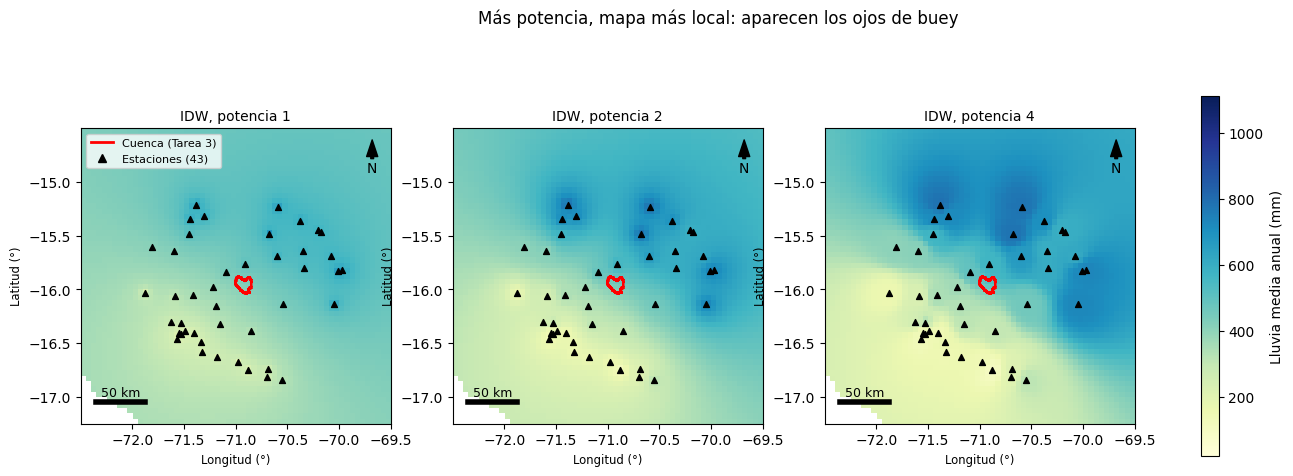

In [156]:
# Mapa 2: cómo cambia el IDW con la potencia (1, 2 y 4)
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, p in zip(axes, [1, 2, 4]):
    img = ax.imshow(idw[p], extent=extent, cmap="YlGnBu", vmin=vmin, vmax=vmax)
    adornos(ax, f"IDW, potencia {p}")
axes[0].legend(handles=leyenda, loc="upper left", fontsize=8)
fig.colorbar(img, ax=axes, label="Lluvia media anual (mm)", shrink=0.85)
fig.suptitle("Más potencia, mapa más local: aparecen los ojos de buey")
plt.show()

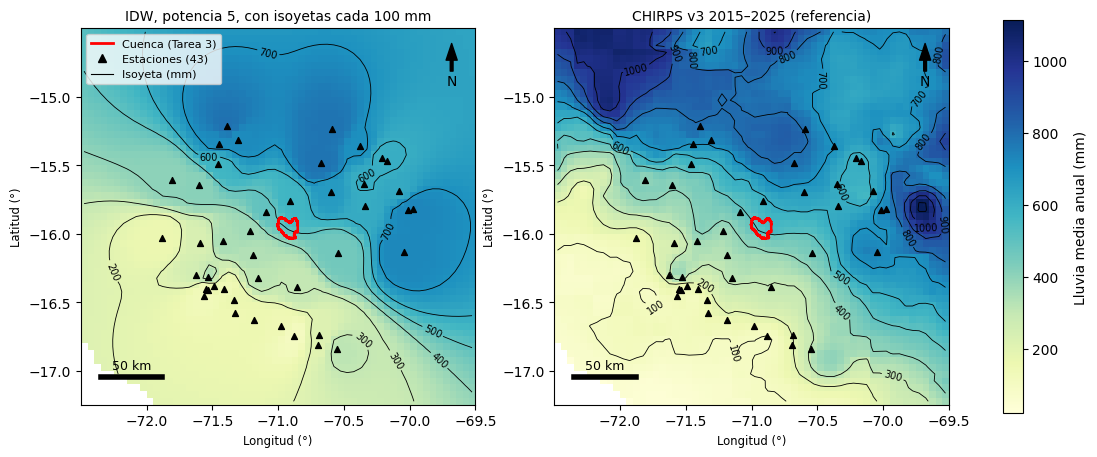

In [157]:
# Mapa 3: isoyetas sobre el IDW, junto a CHIRPS (la referencia)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
X = np.array(lon_c).reshape(filas, cols); Y = np.array(lat_c).reshape(filas, cols)
for ax, (titulo, m) in zip(axes, [(f"IDW, potencia {P_OPTIMA:g}, con isoyetas cada 100 mm", idw_opt),
                                   ("CHIRPS v3 2015–2025 (referencia)", chirps)]):
    img = ax.imshow(m, extent=extent, cmap="YlGnBu", vmin=vmin, vmax=vmax)
    cs = ax.contour(X, Y, m, levels=np.arange(100, 1200, 100), colors="k", linewidths=0.6)
    ax.clabel(cs, fmt="%d", fontsize=7)
    adornos(ax, titulo)
axes[0].legend(handles=leyenda + [Line2D([], [], color="k", lw=0.8, label="Isoyeta (mm)")],
               loc="upper left", fontsize=8)
fig.colorbar(img, ax=axes, label="Lluvia media anual (mm)", shrink=0.85)
plt.show()

### Exportar los resultados

In [158]:
gest.to_file("T04_estaciones_imata.geojson", driver="GeoJSON")
cv.to_csv("T04_validacion_cruzada.csv", index=False)
tabla_cuenca.to_csv("T04_lluvia_media_cuenca.csv")

archivos = [tif_vecino, tif_idw, "T04_estaciones_imata.geojson",
            "T04_validacion_cruzada.csv", "T04_lluvia_media_cuenca.csv"]
with zipfile.ZipFile("T04_Lazaro_Miguel_resultados.zip", "w") as zf:
    for a in archivos:
        zf.write(a)
print("Archivos en el .zip:", archivos)

Archivos en el .zip: ['T04_vecino_imata.tif', 'T04_idw_p5_imata.tif', 'T04_estaciones_imata.geojson', 'T04_validacion_cruzada.csv', 'T04_lluvia_media_cuenca.csv']


## 5. Interpretación

**¿Qué método y qué potencia se eligieron, y por qué?**
Se eligio el IDW con potencia 5 porque tuvo el menor error en la validacion cruzada: 55,7 mm, un 23% menos que el vecino mas cercano. Una potencia alta deja mandar a la estacion mas proxima y respeta el cambio brusco de lluvia entre la vertiente seca de Arequipa y el altiplano de Puno.

**¿Cuánto llueve sobre la cuenca y cuánto depende del método?**
Sobre la cuenca, en la puna de Caylloma donde nace el Sumbay, caen unos 500mm/año. El rango va desde 426.7 a 525.5 mm, lo que nos da 98.8 mm,≈ 19.6 % del valor de CHIRPS.


**¿Qué parte del resultado genera dudas?**
Genera dudas que la lluvia de las estaciones salga de CHIRPS: coincidir con CHIRPS en 1% no prueba que acierte en la puna. Ademas, ninguna estacion esta dentro de la cuenca (imata esta a 12 km) y esta equivale a solo 6,4 celdas: Casi un punto disfrazado de mapa.

## Celda de resumen

In [159]:
print("N_ESTACIONES           =", len(est))
print("P_OPTIMA               =", P_OPTIMA)
print("ERROR_VECINO_MM        =", round(ERROR_VECINO_MM, 1))
print("ERROR_IDW_MM           =", round(ERROR_IDW_MM, 1))
print("LLUVIA_MIN_MAX         =", LLUVIA_MIN_MAX)
print("CELDAS_CUENCA          =", CELDAS_CUENCA)
print("LLUVIA_MEDIA_CUENCA_MM =", LLUVIA_MEDIA_CUENCA_MM)

N_ESTACIONES           = 43
P_OPTIMA               = 5.0
ERROR_VECINO_MM        = 71.9
ERROR_IDW_MM           = 55.7
LLUVIA_MIN_MAX         = (104.2, 785.2)
CELDAS_CUENCA          = 14
LLUVIA_MEDIA_CUENCA_MM = 499.5
